In [1]:
import copy
import os
import sys
import time

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

# add the project folder to the path to be able to import the loader and the model
sys.path.append(os.path.abspath(".."))
from loader.data_loader import get_data_loaders, IMAGE_SIZE
from models import vit_linear_probe, vit_lora, resnet50_linear_probe

# use the GPU if there is one
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


## Load the data

In [2]:
# create the dataloaders for the training, validation and test sets
train_loader, val_loader, test_loader, classes = get_data_loaders(batch_size=32, num_workers=4)

print("Image size:", IMAGE_SIZE)
print("Classes:", classes)
print("Train / validation / test images:", len(train_loader.dataset), len(val_loader.dataset), len(test_loader.dataset))

Image size: 128
Classes: ['1960s', '1970s', '1980s', '1990s', '2000s', '2010s']
Train / validation / test images: 13986 2994 3006


## Load the model

In [3]:
# select a model type and if weights should be loaded
model_type = "vit_linear"  # "vit_linear", "vit_lora" or "resnet_linear"
load_weights = False  # True: start from the weights the save cell at the end saved for this model type

# LoRA settings (only used for "vit_lora")
RANK = 8
ALPHA = 16

# the save cell at the end saves the model here, and load_weights loads it from here
SAVE_PATH = f"../models/saved_models/{model_type}.pt"

# If LOAD_PATH is None, the model will be loaded from SAVE_PATH. Otherwise, it will be loaded from LOAD_PATH.
# LOAD_PATH = None
LOAD_PATH = f"../models/saved_models/vit_linear_swag.pt"

if load_weights:
    # each model type has its own load_model function
    if model_type == "vit_linear":
        model, checkpoint = vit_linear_probe.load_model(SAVE_PATH, device) if LOAD_PATH is None else vit_linear_probe.load_model(LOAD_PATH, device)
    elif model_type == "vit_lora":
        model, checkpoint = vit_lora.load_model(SAVE_PATH, device) if LOAD_PATH is None else vit_lora.load_model(LOAD_PATH, device)
        RANK = checkpoint["rank"]
        ALPHA = checkpoint["alpha"]
    elif model_type == "resnet_linear":
        model, checkpoint = resnet50_linear_probe.load_model(SAVE_PATH, device) if LOAD_PATH is None else resnet50_linear_probe.load_model(LOAD_PATH, device)
    else:
        raise ValueError(f"Unknown model_type: {model_type}")

    # the data loader has to give the images in the size the model was trained with
    if checkpoint["image_size"] != IMAGE_SIZE:
        raise ValueError(f"The saved model was trained with {checkpoint['image_size']}x{checkpoint['image_size']} images, but IMAGE_SIZE is {IMAGE_SIZE}")
    print("Loaded the saved weights from", SAVE_PATH)
else:
    # a new model with the pretrained weights
    if model_type == "vit_linear":
        model = vit_linear_probe.create_model(len(classes), IMAGE_SIZE)
    elif model_type == "vit_lora":
        model = vit_lora.create_model(len(classes), IMAGE_SIZE, RANK, ALPHA)
    elif model_type == "resnet_linear":
        model = resnet50_linear_probe.create_model(len(classes))
    else:
        raise ValueError(f"Unknown model_type: {model_type}")
    model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {trainable:,} of {total:,}")

Trainable parameters: 6,150 of 303,172,614


## Quick test with one batch

In [4]:
images, labels = next(iter(train_loader))

# eval mode for the test, so the BatchNorm layers of the ResNet don't change
model.eval()
with torch.no_grad():
    outputs = model(images.to(device))

print("Input:", images.shape)    # (batch size, colour channels, height, width)
print("Output:", outputs.shape)  # one score per decade for every image

Input: torch.Size([32, 3, 128, 128])
Output: torch.Size([32, 6])


## Train the model

In [5]:
loss_function = nn.CrossEntropyLoss()

# small learning rate
LEARNING_RATE = 0.0005

# the optimizer only gets the trainable parameters (the frozen ones have requires_grad = False)
trainable_params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.Adam(trainable_params, lr=LEARNING_RATE)


def predict(model, loader):
    # runs the model on all images of a loader, returns the true labels and the predictions
    model.eval()
    all_labels = []
    all_predictions = []
    with torch.no_grad():
        for images, labels in loader:
            # bfloat16 (16 bit numbers) makes the model faster and uses less GPU memory
            with torch.autocast(device_type=device, dtype=torch.bfloat16):
                outputs = model(images.to(device))
            all_predictions += outputs.argmax(dim=1).cpu().tolist()
            all_labels += labels.tolist()
    return all_labels, all_predictions


def accuracy(labels, predictions):
    # calculates the accuracy of the predictions compared to the true labels
    correct = sum(1 for label, prediction in zip(labels, predictions) if label == prediction)
    return correct / len(labels)


def get_trained_weights(model):
    # returns a copy of the weights that get trained, in the form the save_model function of the model file expects
    if model_type == "vit_linear":
        return copy.deepcopy(model.heads.head.state_dict())  # only the new last layer
    elif model_type == "resnet_linear":
        return copy.deepcopy(model.fc.state_dict())  # only the new last layer
    elif model_type == "vit_lora":
        # the LoRA matrices + the new last layer = all parameters with requires_grad = True
        return {name: param.detach().clone() for name, param in model.named_parameters() if param.requires_grad}


def set_trained_weights(model, weights):
    # puts weights from get_trained_weights back into the model
    if model_type == "vit_linear":
        model.heads.head.load_state_dict(weights)
    elif model_type == "resnet_linear":
        model.fc.load_state_dict(weights)
    elif model_type == "vit_lora":
        # strict=False because the weights only contain the LoRA matrices and the last layer
        model.load_state_dict(weights, strict=False)

In [6]:
EPOCHS = 20    # maximum number of epochs
PATIENCE = 3   # stop when the validation accuracy did not improve for this many epochs

history = {"train_loss": [], "train_acc": [], "val_acc": []}

# for early stopping
best_val_acc = 0
best_epoch = 0
best_weights = None
epochs_without_improvement = 0

for epoch in range(EPOCHS):
    if model_type == "resnet_linear":
        # the frozen ResNet has to stay in eval mode: in training mode its BatchNorm layers would keep
        # changing, so the frozen part would not stay frozen
        # (eval mode does not turn off the gradients, so the new last layer still learns)
        model.eval()
    else:
        model.train()
    start = time.time()
    total_loss = 0
    correct = 0
    seen = 0

    for i, (images, labels) in enumerate(train_loader):
        # go through the training batches
        images, labels = images.to(device), labels.to(device)

        # forward pass
        # we use autocast here because it makes the model faster and uses less GPU memory, without losing accuracy
        with torch.autocast(device_type=device, dtype=torch.bfloat16):
            outputs = model(images)
            loss = loss_function(outputs, labels)

        # backward pass, this only updates the trainable weights
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        seen += labels.size(0)

        if (i + 1) % 100 == 0:
            print(f"  batch {i + 1}/{len(train_loader)} - loss: {total_loss / seen:.3f}")

    # check how well the model does on the validation set after every epoch
    val_labels, val_predictions = predict(model, val_loader)
    val_acc = accuracy(val_labels, val_predictions)

    history["train_loss"].append(total_loss / seen)
    history["train_acc"].append(correct / seen)
    history["val_acc"].append(val_acc)
    print(f"Epoch {epoch + 1}/{EPOCHS} - loss: {history['train_loss'][-1]:.3f}"
          f" - train acc: {history['train_acc'][-1]:.3f} - val acc: {val_acc:.3f}"
          f" - {time.time() - start:.0f}s")

    # early stopping: remember the best model, stop when it doesn't get better anymore
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch + 1
        # copy of only the trained weights (see get_trained_weights)
        best_weights = get_trained_weights(model)
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement == PATIENCE:
            print(f"No improvement for {PATIENCE} epochs, stopping early.")
            break

# go back to the weights of the best epoch
set_trained_weights(model, best_weights)
print(f"Best validation accuracy: {best_val_acc:.3f} (epoch {best_epoch})")

  batch 100/438 - loss: 1.501
  batch 200/438 - loss: 1.411
  batch 300/438 - loss: 1.354
  batch 400/438 - loss: 1.318
Epoch 1/20 - loss: 1.311 - train acc: 0.449 - val acc: 0.520 - 53s
  batch 100/438 - loss: 1.138
  batch 200/438 - loss: 1.130
  batch 300/438 - loss: 1.124
  batch 400/438 - loss: 1.126
Epoch 2/20 - loss: 1.124 - train acc: 0.536 - val acc: 0.529 - 53s
  batch 100/438 - loss: 1.078
  batch 200/438 - loss: 1.063
  batch 300/438 - loss: 1.065
  batch 400/438 - loss: 1.061
Epoch 3/20 - loss: 1.065 - train acc: 0.567 - val acc: 0.549 - 52s
  batch 100/438 - loss: 1.022
  batch 200/438 - loss: 1.022
  batch 300/438 - loss: 1.020
  batch 400/438 - loss: 1.024
Epoch 4/20 - loss: 1.027 - train acc: 0.581 - val acc: 0.551 - 52s
  batch 100/438 - loss: 0.992
  batch 200/438 - loss: 1.009
  batch 300/438 - loss: 1.004
  batch 400/438 - loss: 0.998
Epoch 5/20 - loss: 1.002 - train acc: 0.593 - val acc: 0.562 - 52s
  batch 100/438 - loss: 0.988
  batch 200/438 - loss: 0.978
  bat

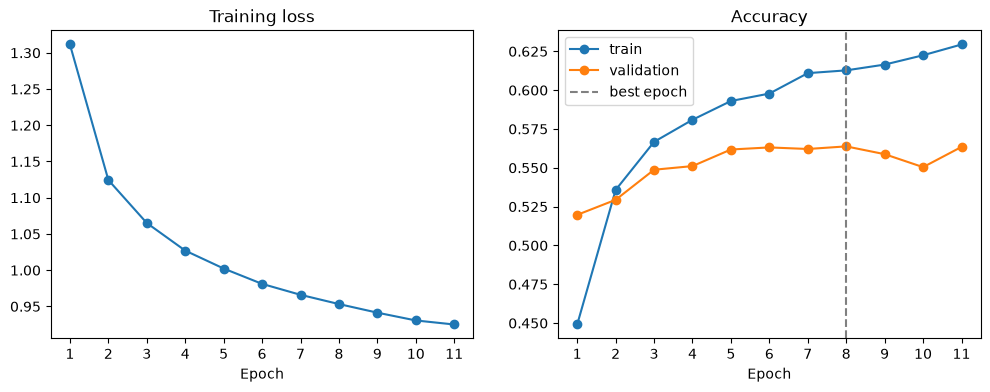

In [7]:
# training can stop early, so use the number of epochs that actually ran
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], marker="o")
plt.title("Training loss")
plt.xlabel("Epoch")
plt.xticks(epochs)

plt.subplot(1, 2, 2)
plt.plot(epochs, history["train_acc"], marker="o", label="train")
plt.plot(epochs, history["val_acc"], marker="o", label="validation")
plt.axvline(best_epoch, color="gray", linestyle="--", label="best epoch")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.xticks(epochs)
plt.legend()

plt.show()

## Test the model

In [8]:
test_labels, test_predictions = predict(model, test_loader)
print(f"Test accuracy: {accuracy(test_labels, test_predictions):.3f}  (random guessing: {1 / len(classes):.3f})")

# accuracy for every decade
results = pd.DataFrame({
    "decade": [classes[i] for i in test_labels],
    "predicted": [classes[i] for i in test_predictions],
})
results["correct"] = results["decade"] == results["predicted"]
results.groupby("decade")["correct"].mean()

Test accuracy: 0.561  (random guessing: 0.167)


decade
1960s    0.638723
1970s    0.499002
1980s    0.564870
1990s    0.483034
2000s    0.500998
2010s    0.676647
Name: correct, dtype: float64

In [9]:
# rows = true decade, columns = predicted decade
pd.crosstab(results["decade"], results["predicted"])

predicted,1960s,1970s,1980s,1990s,2000s,2010s
decade,,,,,,
1960s,320,140,25,6,4,6
1970s,112,250,98,15,9,17
1980s,37,92,283,54,19,16
1990s,13,19,81,242,99,47
2000s,1,8,23,92,251,126
2010s,3,7,13,22,117,339


## Show some test predictions

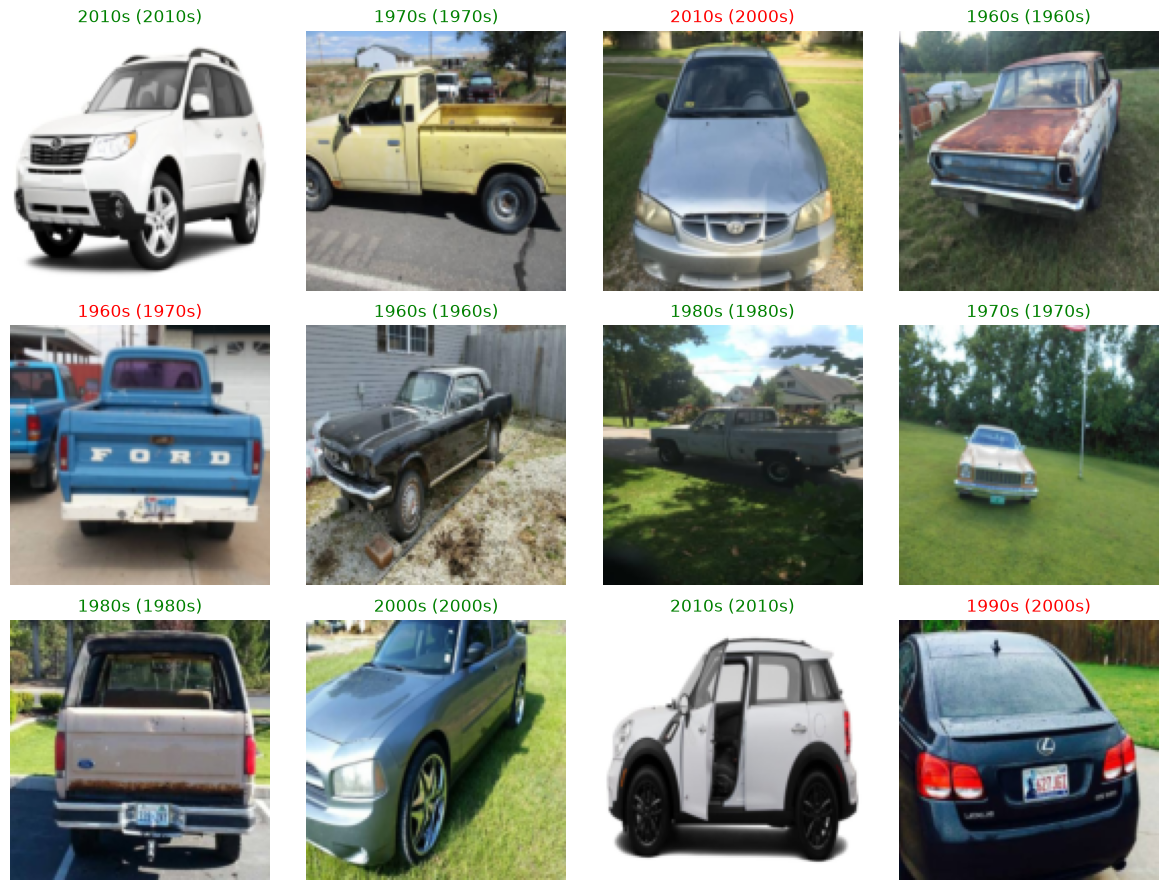

In [10]:
# same mean and std as in the data loader, used to undo the normalization
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# the test loader is sorted by decade, so we shuffle it to get a mix of decades
images, labels = next(iter(DataLoader(test_loader.dataset, batch_size=12, shuffle=True)))

model.eval()
with torch.no_grad():
    outputs = model(images.to(device))
predictions = outputs.argmax(dim=1).cpu()

# title = predicted decade (true decade), green if correct and red if wrong
plt.figure(figsize=(12, 9))
for i in range(12):
    image = (images[i] * std + mean).permute(1, 2, 0) # permute for matplotlib
    color = "green" if predictions[i] == labels[i] else "red"

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(f"{classes[predictions[i]]} ({classes[labels[i]]})", color=color)
    plt.axis("off")
plt.tight_layout()
plt.show()

## Save the model weights

In [ ]:
os.makedirs("../models/saved_models", exist_ok=True)

# the image size is saved too, so the model can be built the same way when loading it

if model_type == "vit_linear":
    vit_linear_probe.save_model(SAVE_PATH, best_weights, IMAGE_SIZE, classes)
elif model_type == "vit_lora":
    vit_lora.save_model(SAVE_PATH, best_weights, IMAGE_SIZE, RANK, ALPHA, classes)
elif model_type == "resnet_linear":
    resnet50_linear_probe.save_model(SAVE_PATH, best_weights, IMAGE_SIZE, classes)

print(f"Saved to {os.path.abspath(SAVE_PATH)}")